In [1]:
import torch
import torch.nn.functional as F

from torch_geometric.nn import GCNConv

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

C:\Users\nakul\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cpu


In [3]:
GRAPH_PATH = "../data/processed/elliptic_graph.pt"

graph_data = torch.load(
    GRAPH_PATH,
    weights_only=False
)

print(graph_data)

Data(x=[203769, 165], edge_index=[2, 468710], y=[203769], train_mask=[203769], val_mask=[203769], test_mask=[203769])


In [4]:
print("Node features :", graph_data.x.shape)
print("Edges         :", graph_data.edge_index.shape)
print("Labels        :", graph_data.y.shape)

print("\nTrain nodes :", graph_data.train_mask.sum().item())
print("Valid nodes :", graph_data.val_mask.sum().item())
print("Test nodes  :", graph_data.test_mask.sum().item())

Node features : torch.Size([203769, 165])
Edges         : torch.Size([2, 468710])
Labels        : torch.Size([203769])

Train nodes : 29894
Valid nodes : 7829
Test nodes  : 8841


In [5]:
# Load graph_data ✅
#        ↓
# Define 2-layer GCN       ← NEXT
#        ↓
# Loss + optimizer
#        ↓
# Training loop
#        ↓
# Validation
#        ↓
# Test evaluation
#        ↓
# Save trained model
#        ↓
# GNNExplainer
#        ↓
# App

# Verify labels

In [6]:
print(
    "Unique labels:",
    torch.unique(graph_data.y)
)

Unique labels: tensor([-1,  0,  1])


In [7]:
unique_labels, counts = torch.unique(
    graph_data.y,
    return_counts=True
)

for label, count in zip(unique_labels, counts):
    print(
        f"Label {label.item()}: {count.item()} nodes"
    )

Label -1: 157205 nodes
Label 0: 42019 nodes
Label 1: 4545 nodes


In [8]:
train_labels = graph_data.y[
    graph_data.train_mask
]

unique_labels, counts = torch.unique(
    train_labels,
    return_counts=True
)

print("\nTraining label distribution:")

for label, count in zip(unique_labels, counts):
    print(
        f"Label {label.item()}: {count.item()}"
    )


Training label distribution:
Label 0: 26432
Label 1: 3462


In [9]:
graph_data = graph_data.to(device)

# Define our first GCN

In [10]:
class GCN(torch.nn.Module):

    def __init__(
        self,
        num_features,
        hidden_channels,
        num_classes
    ):

        super().__init__()

        self.conv1 = GCNConv(
            num_features,
            hidden_channels
        )

        self.conv2 = GCNConv(
            hidden_channels,
            num_classes
        )

    def forward(
        self,
        x,
        edge_index
    ):

        # First graph convolution
        x = self.conv1(
            x,
            edge_index
        )

        # Non-linearity
        x = F.relu(x)

        # Reduce overfitting
        x = F.dropout(
            x,
            p=0.5,
            training=self.training
        )

        # Final graph convolution
        x = self.conv2(
            x,
            edge_index
        )

        return x

# Create the model

In [11]:
num_features = graph_data.x.shape[1]

print("Number of input features:", num_features)

Number of input features: 165


In [12]:
num_classes = 2
hidden_channels = 64

In [13]:
model = GCN(
    num_features=num_features,
    hidden_channels=hidden_channels,
    num_classes=num_classes
).to(device)

print(model)

GCN(
  (conv1): GCNConv(165, 64)
  (conv2): GCNConv(64, 2)
)


In [14]:
# What is actually happening here?
# This part:
# self.conv1 = GCNConv(    num_features,    64)


# means every transaction starts with something like:
# Transaction A
# [feature1, feature2, ... feature165]

# GCN doesn't examine Transaction A alone.
# It aggregates information from its graph neighborhood:
#              Transaction B
#                     ↓
# Transaction C → Transaction A ← Transaction D
#                     ↑
#              Transaction E

# Conceptually:
# A's own features
#         +
# features from neighboring transactions
#         ↓
#         GCN
#         ↓
# new representation of A

# So after the first layer:
# 165 original features
#         ↓
# 64 learned graph-aware features

# Those 64 values are no longer ordinary dataset columns. They're embeddings learned by the network.
# Then:
# self.conv2 = GCNConv(    64,    2)


# converts that learned representation into two scores:
# [score_class_0, score_class_1]

# For example:
# [-1.2, 2.8]

# would indicate the second class is preferred.

In [15]:
print(torch.unique(graph_data.y))

tensor([-1,  0,  1])


In [16]:
unique_labels, counts = torch.unique(
    graph_data.y[graph_data.train_mask],
    return_counts=True
)

for label, count in zip(unique_labels, counts):
    print(label.item(), count.item())

0 26432
1 3462


In [17]:
train_labels = graph_data.y[
    graph_data.train_mask
]

class_counts = torch.bincount(train_labels)

print("Class counts:", class_counts)

Class counts: tensor([26432,  3462])


In [18]:
CLASS_WEIGHTS_PATH = "../data/processed/class_weights.pt"

class_weights = torch.load(
    CLASS_WEIGHTS_PATH,
    weights_only=True
).to(device)

print("Loaded class weights:", class_weights)

Loaded class weights: tensor([0.5655, 4.3174])


In [19]:
criterion = torch.nn.CrossEntropyLoss(
    weight=class_weights
)

In [20]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01,
    weight_decay=5e-4
)

# training function:

In [21]:
def train():
    model.train()

    optimizer.zero_grad()

    out = model(
        graph_data.x,
        graph_data.edge_index
    )

    loss = criterion(
        out[graph_data.train_mask],
        graph_data.y[graph_data.train_mask]
    )

    loss.backward()

    optimizer.step()

    return loss.item()

# add a prediction helper:

In [22]:
@torch.no_grad()
def predict(mask):

    model.eval()

    out = model(
        graph_data.x,
        graph_data.edge_index
    )

    predictions = out.argmax(dim=1)

    y_true = graph_data.y[mask]
    y_pred = predictions[mask]

    return y_true, y_pred

In [23]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def evaluate(mask):
    y_true, y_pred = predict(mask)

    y_true = y_true.cpu().numpy()
    y_pred = y_pred.cpu().numpy()

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "f1": f1_score(y_true, y_pred, pos_label=1, zero_division=0)
    }

In [24]:
num_epochs = 100

train_losses = []
val_f1_scores = []

best_val_f1 = 0.0

for epoch in range(1, num_epochs + 1):

    loss = train()

    val_metrics = evaluate(
        graph_data.val_mask
    )

    train_losses.append(loss)
    val_f1_scores.append(
        val_metrics["f1"]
    )

    # Save model only when validation F1 improves
    if val_metrics["f1"] > best_val_f1:

        best_val_f1 = val_metrics["f1"]

        torch.save(
            model.state_dict(),
            "best_gcn_model.pt"
        )

    if epoch % 10 == 0 or epoch == 1:

        print(
            f"Epoch {epoch:03d} | "
            f"Loss: {loss:.4f} | "
            f"Val Acc: {val_metrics['accuracy']:.4f} | "
            f"Val Precision: {val_metrics['precision']:.4f} | "
            f"Val Recall: {val_metrics['recall']:.4f} | "
            f"Val F1: {val_metrics['f1']:.4f}"
        )

print(
    "\nBest Validation F1:",
    best_val_f1
)

Epoch 001 | Loss: 0.7730 | Val Acc: 0.6522 | Val Precision: 0.1806 | Val Recall: 0.8578 | Val F1: 0.2984
Epoch 010 | Loss: 0.3143 | Val Acc: 0.7958 | Val Precision: 0.2387 | Val Recall: 0.6252 | Val F1: 0.3455
Epoch 020 | Loss: 0.2591 | Val Acc: 0.8305 | Val Precision: 0.3000 | Val Recall: 0.7244 | Val F1: 0.4243
Epoch 030 | Loss: 0.2229 | Val Acc: 0.8520 | Val Precision: 0.3378 | Val Recall: 0.7467 | Val F1: 0.4652
Epoch 040 | Loss: 0.2060 | Val Acc: 0.8681 | Val Precision: 0.3686 | Val Recall: 0.7437 | Val F1: 0.4929
Epoch 050 | Loss: 0.1875 | Val Acc: 0.8751 | Val Precision: 0.3839 | Val Recall: 0.7422 | Val F1: 0.5061
Epoch 060 | Loss: 0.1821 | Val Acc: 0.8789 | Val Precision: 0.3916 | Val Recall: 0.7304 | Val F1: 0.5098
Epoch 070 | Loss: 0.1680 | Val Acc: 0.8900 | Val Precision: 0.4191 | Val Recall: 0.7141 | Val F1: 0.5282
Epoch 080 | Loss: 0.1608 | Val Acc: 0.8976 | Val Precision: 0.4417 | Val Recall: 0.7126 | Val F1: 0.5454
Epoch 090 | Loss: 0.1523 | Val Acc: 0.9013 | Val Precis

In [25]:
model.load_state_dict(
    torch.load(
        "best_gcn_model.pt",
        map_location=device
    )
)

model.eval()

GCN(
  (conv1): GCNConv(165, 64)
  (conv2): GCNConv(64, 2)
)

In [26]:
test_metrics = evaluate(graph_data.test_mask)

print("\nTest Results")
print("Accuracy :", test_metrics["accuracy"])
print("Precision:", test_metrics["precision"])
print("Recall   :", test_metrics["recall"])
print("F1 Score :", test_metrics["f1"])


Test Results
Accuracy : 0.9515891867435811
Precision: 0.4731182795698925
Recall   : 0.43137254901960786
F1 Score : 0.4512820512820513


# add a full classification report:

In [27]:
from sklearn.metrics import classification_report

y_true, y_pred = predict(graph_data.test_mask)

print(
    classification_report(
        y_true.cpu().numpy(),
        y_pred.cpu().numpy(),
        target_names=["Legitimate", "Fraud"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

  Legitimate       0.97      0.98      0.97      8433
       Fraud       0.47      0.43      0.45       408

    accuracy                           0.95      8841
   macro avg       0.72      0.70      0.71      8841
weighted avg       0.95      0.95      0.95      8841



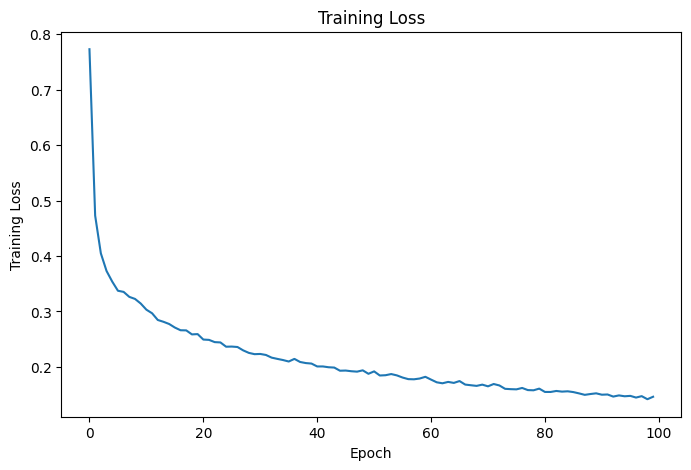

In [28]:
plt.figure(figsize=(8, 5))
plt.plot(train_losses)
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss")
plt.show()

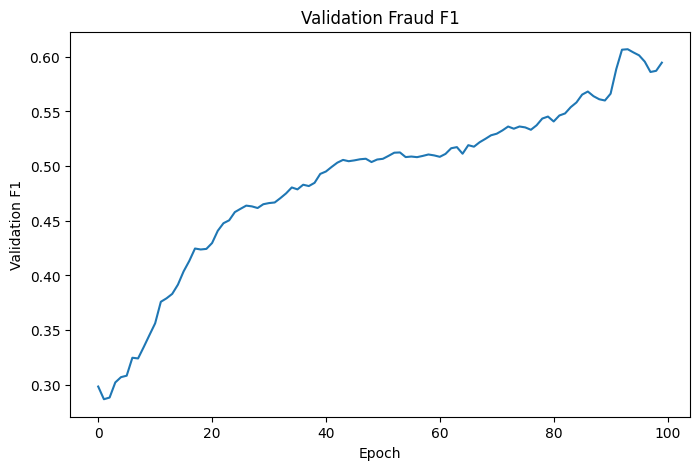

In [29]:
plt.figure(figsize=(8, 5))
plt.plot(val_f1_scores)
plt.xlabel("Epoch")
plt.ylabel("Validation F1")
plt.title("Validation Fraud F1")
plt.show()

# Confusion Matrix

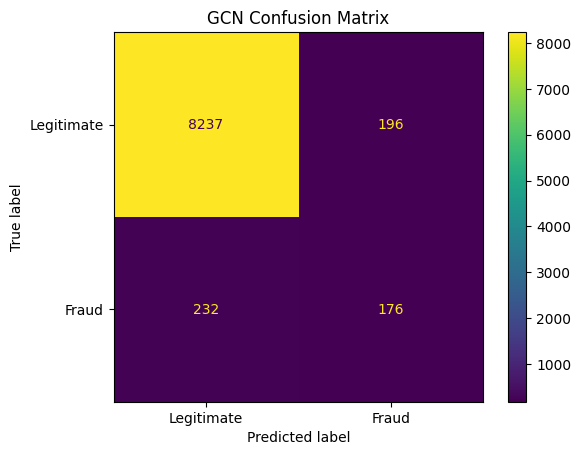

In [30]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_true, y_pred = predict(graph_data.test_mask)

cm = confusion_matrix(
    y_true.cpu().numpy(),
    y_pred.cpu().numpy()
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate", "Fraud"]
)

disp.plot()
plt.title("GCN Confusion Matrix")
plt.show()

# GNNExplainer.

In [31]:
model.load_state_dict(
    torch.load(
        "best_gcn_model.pt",
        map_location=device
    )
)

model.eval()

GCN(
  (conv1): GCNConv(165, 64)
  (conv2): GCNConv(64, 2)
)

In [32]:
with torch.no_grad():
    out = model(
        graph_data.x,
        graph_data.edge_index
    )

    predictions = out.argmax(dim=1)

In [33]:
correct_fraud_nodes = torch.where(
    (graph_data.test_mask) &
    (graph_data.y == 1) &
    (predictions == 1)
)[0]

print(
    "Correctly predicted fraud nodes:",
    len(correct_fraud_nodes)
)

print(
    "First few:",
    correct_fraud_nodes[:10]
)

Correctly predicted fraud nodes: 176
First few: tensor([166967, 167101, 167221, 167298, 167322, 167404, 167519, 167533, 167640,
        167693])


In [34]:
node_idx = correct_fraud_nodes[0].item()

print("Selected node:", node_idx)
print("True label:", graph_data.y[node_idx].item())
print("Predicted label:", predictions[node_idx].item())

Selected node: 166967
True label: 1
Predicted label: 1


In [35]:
from torch_geometric.explain import Explainer, GNNExplainer

In [36]:
explainer = Explainer(
    model=model,

    algorithm=GNNExplainer(
        epochs=100
    ),

    explanation_type="model",

    node_mask_type="attributes",

    edge_mask_type="object",

    model_config=dict(
        mode="multiclass_classification",
        task_level="node",
        return_type="raw"
    )
)

In [37]:
explanation = explainer(
    graph_data.x,
    graph_data.edge_index,
    index=node_idx
)

In [38]:
print(explanation)

Explanation(node_mask=[203769, 165], edge_mask=[468710], prediction=[203769, 2], target=[203769], index=[1], x=[203769, 165], edge_index=[2, 468710])


In [39]:
print(
    "Node mask shape:",
    explanation.node_mask.shape
)

print(
    "Edge mask shape:",
    explanation.edge_mask.shape
)

Node mask shape: torch.Size([203769, 165])
Edge mask shape: torch.Size([468710])


In [41]:
# Conceptually, GNNExplainer is learning two things:
# Which node features mattered?
#         +
# Which graph connections mattered?

# So if the model sees something like:
# Transaction A
#    ↑       ↑
#    │       │
# Transaction B   Transaction C

# GNNExplainer may discover that the edge:
# B → A
# was much more influential than:
# C → A

In [42]:
print(explanation)
print(explanation.node_mask.shape)
print(explanation.edge_mask.shape)

Explanation(node_mask=[203769, 165], edge_mask=[468710], prediction=[203769, 2], target=[203769], index=[1], x=[203769, 165], edge_index=[2, 468710])
torch.Size([203769, 165])
torch.Size([468710])


## Top features for the selected fraud node

In [43]:
feature_importance = explanation.node_mask[node_idx]

top_k = 10

top_values, top_indices = torch.topk(
    feature_importance,
    k=top_k
)

print("Top important features:\n")

for rank, (feature_idx, importance) in enumerate(
    zip(top_indices, top_values),
    start=1
):
    print(
        f"{rank}. Feature {feature_idx.item()} "
        f"-> Importance: {importance.item():.4f}"
    )

Top important features:

1. Feature 52 -> Importance: 0.7150
2. Feature 111 -> Importance: 0.7080
3. Feature 164 -> Importance: 0.7067
4. Feature 131 -> Importance: 0.7042
5. Feature 150 -> Importance: 0.6995
6. Feature 53 -> Importance: 0.6990
7. Feature 157 -> Importance: 0.6935
8. Feature 10 -> Importance: 0.6921
9. Feature 51 -> Importance: 0.6895
10. Feature 88 -> Importance: 0.6859


In [46]:
## Find the most important graph connections

In [47]:
edge_importance = explanation.edge_mask

top_k_edges = 10

top_edge_values, top_edge_indices = torch.topk(
    edge_importance,
    k=top_k_edges
)

print("Top important edges:\n")

for rank, (edge_idx, importance) in enumerate(
    zip(top_edge_indices, top_edge_values),
    start=1
):

    source = graph_data.edge_index[0, edge_idx].item()
    target = graph_data.edge_index[1, edge_idx].item()

    print(
        f"{rank}. {source} -> {target} "
        f"| Importance: {importance.item():.4f}"
    )

Top important edges:

1. 167640 -> 167299 | Importance: 0.7886
2. 168076 -> 167299 | Importance: 0.7883
3. 168084 -> 167299 | Importance: 0.7883
4. 171885 -> 167299 | Importance: 0.7882
5. 168701 -> 167299 | Importance: 0.7878
6. 169427 -> 167299 | Importance: 0.7876
7. 168274 -> 167299 | Importance: 0.7876
8. 169369 -> 167299 | Importance: 0.7876
9. 169938 -> 167299 | Importance: 0.7876
10. 168875 -> 167299 | Importance: 0.7876


In [48]:
source_nodes = graph_data.edge_index[0]
target_nodes = graph_data.edge_index[1]

connected_mask = (
    (source_nodes == node_idx) |
    (target_nodes == node_idx)
)

connected_edge_indices = torch.where(
    connected_mask
)[0]

print(
    "Directly connected edges:",
    len(connected_edge_indices)
)

Directly connected edges: 6


## rank those edges by GNNExplainer importance:

In [50]:
connected_importance = edge_importance[
    connected_edge_indices
]

k = min(
    10,
    len(connected_edge_indices)
)

values, positions = torch.topk(
    connected_importance,
    k=k
)

print("\nMost influential direct connections:\n")

for rank, (position, importance) in enumerate(
    zip(positions, values),
    start=1
):

    edge_idx = connected_edge_indices[position]

    source = graph_data.edge_index[
        0, edge_idx
    ].item()

    target = graph_data.edge_index[
        1, edge_idx
    ].item()

    neighbor = (
        target
        if source == node_idx
        else source
    )

    print(
        f"{rank}. Neighbor node {neighbor} "
        f"| Edge importance: {importance.item():.4f}"
    )


Most influential direct connections:

1. Neighbor node 166966 | Edge importance: 0.7651
2. Neighbor node 173663 | Edge importance: 0.7238
3. Neighbor node 173663 | Edge importance: 0.6939
4. Neighbor node 167299 | Edge importance: 0.6913
5. Neighbor node 166966 | Edge importance: 0.5436
6. Neighbor node 167299 | Edge importance: 0.2250


In [51]:
# This second output is much more useful for our project because now we can say something like:
# Transaction X was predicted as fraudulent partly because of its relationship with transactions A, B, and C.

# And together with the feature explanation:
#                   FRAUD PREDICTION
#                          │
#           ┌──────────────┴──────────────┐
#           │                             │
#      Feature-level                 Graph-level
#      explanation                   explanation
#           │                             │
#    Feature 53: 0.81             Neighbor 7241: 0.92
#    Feature 12: 0.76             Neighbor 8192: 0.73
#    Feature 91: 0.70             Neighbor 4421: 0.61

# That's already the core of the explainable fraud detection part of V1.

In [52]:
print("Selected node:", node_idx)
print("Number of direct connections:", connected_mask.sum().item())

print(
    "Non-zero explanation edges:",
    (explanation.edge_mask > 0).sum().item()
)

Selected node: 166967
Number of direct connections: 6
Non-zero explanation edges: 32


## The next step is to make the explanation more 
## interpretable by deduplicating direct neighbors and aggregating their edge importance.

In [55]:
from collections import defaultdict

neighbor_importance = defaultdict(float)

for edge_idx in connected_edge_indices:

    source = graph_data.edge_index[0, edge_idx].item()
    target = graph_data.edge_index[1, edge_idx].item()

    importance = explanation.edge_mask[edge_idx].item()

    if source == node_idx:
        neighbor = target
    else:
        neighbor = source

    neighbor_importance[neighbor] += importance

In [56]:
sorted_neighbors = sorted(
    neighbor_importance.items(),
    key=lambda x: x[1],
    reverse=True
)

print("Most influential neighboring transactions:\n")

for rank, (neighbor, importance) in enumerate(
    sorted_neighbors[:10],
    start=1
):
    print(
        f"{rank}. Neighbor {neighbor} "
        f"| Combined importance: {importance:.4f}"
    )

Most influential neighboring transactions:

1. Neighbor 173663 | Combined importance: 1.4177
2. Neighbor 166966 | Combined importance: 1.3088
3. Neighbor 167299 | Combined importance: 0.9163


In [57]:
print("Selected node:", node_idx)
print("Selected node label:", graph_data.y[node_idx].item())

print("\nNeighbor information:\n")

for neighbor, importance in sorted_neighbors[:10]:

    label = graph_data.y[neighbor].item()

    if label == 1:
        label_name = "Fraud"
    elif label == 0:
        label_name = "Legitimate"
    else:
        label_name = "Unknown"

    print(
        f"Neighbor {neighbor} "
        f"| Label: {label_name} "
        f"| Importance: {importance:.4f}"
    )

Selected node: 166967
Selected node label: 1

Neighbor information:

Neighbor 173663 | Label: Unknown | Importance: 1.4177
Neighbor 166966 | Label: Unknown | Importance: 1.3088
Neighbor 167299 | Label: Unknown | Importance: 0.9163


## create a small local explanation graph centered on transaction 166967

In [58]:
import networkx as nx
import matplotlib.pyplot as plt

In [59]:
G = nx.Graph()

selected_node = node_idx

G.add_node(
    selected_node,
    label="Fraud"
)

top_neighbors = sorted_neighbors[:5]

for neighbor, importance in top_neighbors:

    neighbor_label = graph_data.y[neighbor].item()

    if neighbor_label == 1:
        label_name = "Fraud"
    elif neighbor_label == 0:
        label_name = "Legitimate"
    else:
        label_name = "Unknown"

    G.add_node(
        neighbor,
        label=label_name
    )

    G.add_edge(
        selected_node,
        neighbor,
        weight=importance
    )

# Top Feature Bar

In [60]:
# Extract top feature importances

In [69]:
top_k = 10

feature_importance = explanation.node_mask[node_idx]

top_values, top_indices = torch.topk(
    feature_importance,
    k=top_k
)

top_values = top_values.detach().cpu().numpy()
top_indices = top_indices.detach().cpu().numpy()

print("Top important features:\n")
for rank, (feature_idx, importance) in enumerate(
    zip(top_indices, top_values),
    start=1
):
    print(
        f"{rank}. Feature {feature_idx} "
        f"| Importance: {importance:.4f}"
    )

Top important features:

1. Feature 52 | Importance: 0.7150
2. Feature 111 | Importance: 0.7080
3. Feature 164 | Importance: 0.7067
4. Feature 131 | Importance: 0.7042
5. Feature 150 | Importance: 0.6995
6. Feature 53 | Importance: 0.6990
7. Feature 157 | Importance: 0.6935
8. Feature 10 | Importance: 0.6921
9. Feature 51 | Importance: 0.6895
10. Feature 88 | Importance: 0.6859


In [63]:
# Plot top-feature bar chart

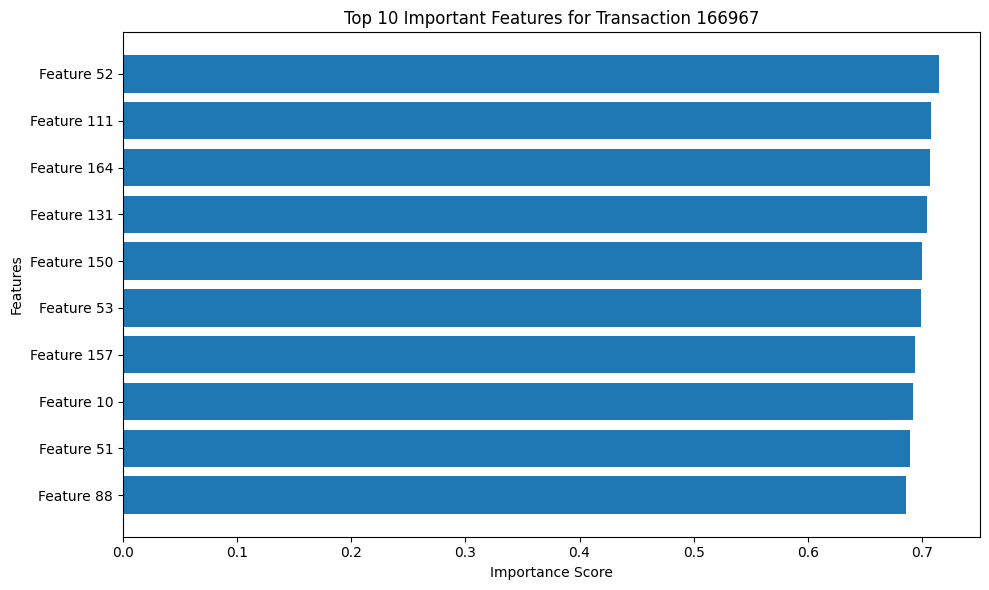

In [71]:
import matplotlib.pyplot as plt

feature_labels = [
    f"Feature {idx}"
    for idx in top_indices
]

plt.figure(figsize=(10, 6))
plt.barh(feature_labels, top_values)
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title(f"Top {top_k} Important Features for Transaction {node_idx}")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()